## Computational Homework 2, 2026

#### Due September 23

Unless expressly stated otherwise, please make sure your plot axes have labels and multiple lines on the same plot are explained in a legend.

#### Including friction in Lagrangian mechanics

<ol>
    <li>Assume a single particle moving in one dimension is subjected to a net <bf>conservative</bf> force \[ F = -\frac{\partial U}{\partial x} \] and a friction force $F_{\rm fric}$. Define the Lagrangian as \[\mathcal{L} =  \mathcal{T} - U \] and show that the appropriate modification to the Euler-Lagrange equation is \[ \frac{\partial \mathcal{L}}{\partial x} + F_{\rm fric} = \frac{d}{dt} \frac{\partial \mathcal{L}}{\partial \dot{x}}.\] Write out your solution step by step in a Markdown cell in this notebook (like this one). Markdown syntax is quite similar to LaTeX; see the <a href=https://www.markdownguide.org/basic-syntax/>Markdown guide</a>.</li>
</ol>

<strong>Solution:</strong>

Newtonian mechanics gives us the general equation of motion

##### $m \ddot{x} = \sum_{m=1}^M \vec{F}_m$

for a particle moving along a line. $\sum_{m=1}^M \vec{F}_m$ is the net force given by all $M$ individual forces and the vector direction in $\vec{F}_m$ has two choices: positive or negative.

Our example has a conservative component that can be expressed using the gradient of a potential, $\vec{F} = -\nabla U$, and a non-conservative component $\vec{F}_{\rm fric}$. Thus we need our Lagrangian to deliver the following equation of motion:

##### $m \ddot{x} = -\nabla U + \vec{F}_{\rm fric}.$

For $\mathcal{L} = T - U = \frac{1}{2} m \dot{x}^2 - U(x)$, the conservative component of the force is $\frac{\partial \mathcal{L}}{\partial x} = -\nabla U(x)$ and the rate of change of momentum due <strong>only</strong> to the conservative force would be $\frac{d}{dt} \frac{\partial \mathcal{L}}{\partial \dot{x}}  = m \ddot{x}.$ We get the correct equation of motion if we modify the Euler-Lagrange equation like so:

##### $\frac{\partial \mathcal{L}}{\partial x} + \vec{F}_{\rm fric} = \frac{d}{dt} \frac{\partial \mathcal{L}}{\partial \dot{x}}$.

#### Oscillations about an equilibrium point

Consider Example 7.6 in your textbook, the bead on the spinning wire. Equation 7.69 gives the equation of motion (EOM): $\ddot{\theta} = (\omega^2 \cos \theta - g/R) \sin \theta.$ While the EOM doesn't have an analytical solution, it can be solved numerically. The behavior of the system is determined by the ratio $\frac{\omega^2}{g/R}.$

<ol start=2>
    <li>Choose a value of $\frac{\omega^2}{g/R}$ that is much less than 1. Select a value of $R$ that is of order 1 meter. The exact number is up to you. Start the bead at a small displacement from the equilibrium position at the bottom of the hoop. The exact angle of your displacement is up to you. Use <tt>sympy</tt> to <em>numerically</em> solve your equation of motion to find $\theta(t)$ for 5 full rotations of the hoop. Plot your answer.</li>
    <li>Now pick a value of $\frac{\omega^2}{g/R}$ that is comfortably higher than 1. Again, start the bead at a small displacement from the bottom of the hoop. Use <tt>sympy</tt> to numerically find $\theta(t)$ for five rotations of the hoop and plot your answer. In a Markdown cell, explain how your answer differs from question 2.</li>
</ol>

Solution: Rewrite the EOM as $\ddot{\theta} = \frac{g}{R}(\frac{\omega^2}{g/R} \cos \theta - 1) \sin \theta.$ Then we can use our dimensionless ratio $\eta = \omega^2 R / g$ as a free parameter in the equation.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sympy import symbols, lambdify, cos, sin
from scipy.integrate import solve_ivp
from scipy.constants import g # 9.8 m/s^2

plt.rcParams.update({'font.size':16, 'axes.labelsize':16})
plt.style.use('seaborn-v0_8-deep')

In [2]:
f = symbols('f:2') # f[0] = θ, f[1] = dθ/dt
θ = f[0]
θdot = f[1]

η, t = symbols('η, t') # η = ω^2 / (g/R), t = time (dummy variable)

In [3]:
# Initial value of θ is 10 degrees; initial angular velocity of bead is 0, hoop radius is 1.2 m
θ0 = np.deg2rad(10)
θdot0 = 0
R = 1.2

# EOM translated into two coupled first-order differential equations
fdot = [θdot, (g/R) * (η * cos(θ) - 1) * sin(θ)]
EOM = lambdify((t, f, η), fdot)

For the first experiment, we choose $\eta \ll 1$, then find the integration time corresponding to 5 hoop rotations

In [4]:
η1 = 0.05
ω1 = np.sqrt(η1 * (g/R))
t_max1 = 10*np.pi / ω1

# Numerically solve the differential equation
bead_path_1 = solve_ivp(EOM, [0, t_max1], [θ0, θdot0], args=(η1,), dense_output=True)

Check that the solution was successful

In [5]:
bead_path_1

  message: The solver successfully reached the end of the integration interval.
  success: True
   status: 0
        t: [ 0.000e+00  7.370e-04 ...  4.913e+01  4.915e+01]
        y: [[ 1.745e-01  1.745e-01 ...  9.736e-03  1.830e-02]
            [ 0.000e+00 -9.943e-04 ...  4.838e-01  4.818e-01]]
      sol: <scipy.integrate._ivp.common.OdeSolution object at 0x11bd8a900>
 t_events: None
 y_events: None
     nfev: 872
     njev: 0
      nlu: 0

Plot the bead path

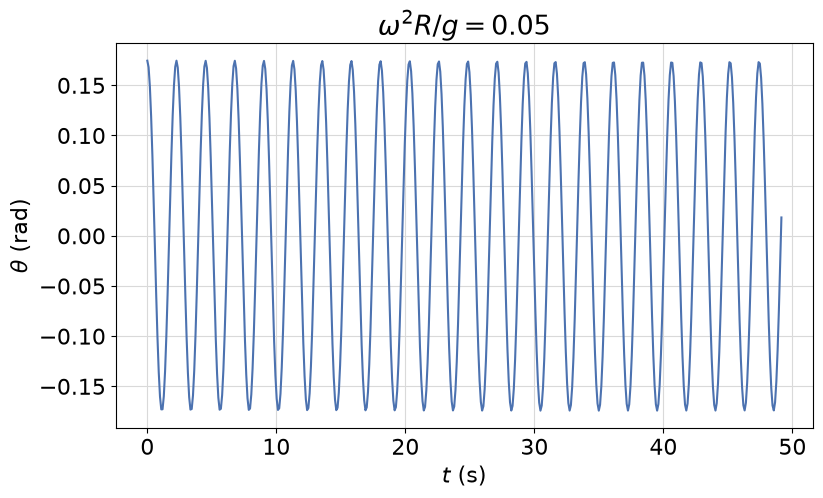

In [6]:
t1 = np.linspace(0, t_max1, num=501)
bp1 = bead_path_1.sol(t1)
plt.figure(figsize=(9,5))
plt.plot(t1, bp1[0])
plt.xlabel(r"$t$ (s)")
plt.ylabel(r"$\theta$ (rad)")
plt.title(r"$\omega^2 R / g = 0.05$")
plt.grid(color='0.85')

For the second setup, set $\eta \gg 1$

In [7]:
η2 = 50
ω2 = np.sqrt(η2 * (g/R))
t_max2 = 10*np.pi / ω2

# Numerically solve the differential equation
bead_path_2 = solve_ivp(EOM, [0, t_max2], [θ0, θdot0], args=(η2,), dense_output=True)

In [8]:
bead_path_2

  message: The solver successfully reached the end of the integration interval.
  success: True
   status: 0
        t: [ 0.000e+00  1.452e-05 ...  1.522e+00  1.554e+00]
        y: [[ 1.745e-01  1.745e-01 ...  1.934e+00  1.311e+00]
            [ 0.000e+00  9.943e-04 ... -1.799e+01 -1.893e+01]]
      sol: <scipy.integrate._ivp.common.OdeSolution object at 0x11bf57250>
 t_events: None
 y_events: None
     nfev: 248
     njev: 0
      nlu: 0

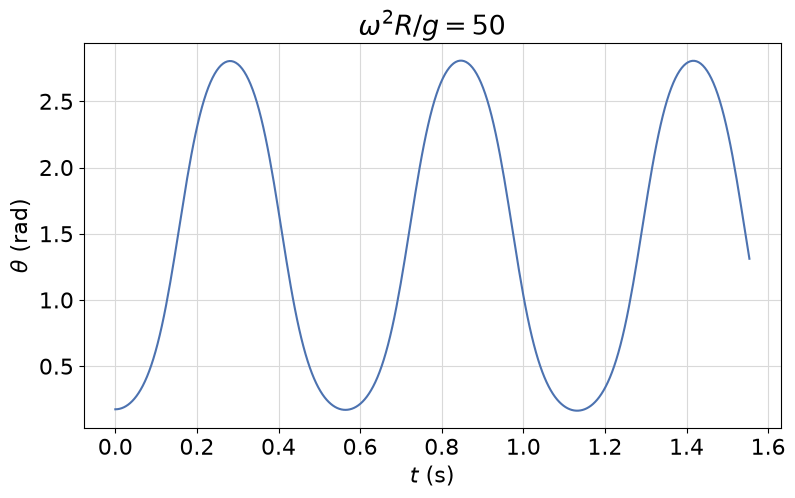

In [9]:
t2 = np.linspace(0, t_max2, num=301)
bp2 = bead_path_2.sol(t2)
plt.figure(figsize=(9,5))
plt.plot(t2, bp2[0])
plt.xlabel(r"$t$ (s)")
plt.ylabel(r"$\theta$ (rad)")
plt.title(r"$\omega^2 R / g = 50$")
plt.grid(color='0.85')

In [10]:
np.rad2deg(0.17)

np.float64(9.740282517223996)

The primary difference is the oscillation amplitude: for small $\eta = \omega^2 / (g/R)$, it's 10 degrees, which is what I set in my initial conditions. For large $\eta$, the hoop rotation pushes the bead to higher $\theta$ instead of letting it return to equilibrium, and the bead oscillation covers most of the circle.

#### Testing <tt>sympy.calculus.euler.euler_equations</tt>

In Figure 7.12 of your textbook, a yoyo is represented by a cylinder of radius $R$ rolling down a string with negligible mass at angular speed $\omega$.

<ol start=4>
    <li>Write the Lagrangian for one generalized coordinate, the vertical distance of the string-cylinder contact point from the yoyo-er's hand, and try to use <tt>sympy.calculus.euler.euler_equations</tt> to find the Euler-Lagrange equation.</li>
    <li>Derive the Euler-Lagrange equation by hand. Does your solution match <tt>sympy</tt>'s solution? If <tt>sympy</tt> was unsuccesful at solving the Euler-Lagrange equation, how might you improve your calculation? Remember that, like any physicist, a computer algebra system likes to be fed information in the simplest form possible.</li>
</ol>

The kinetic energy is $T = \frac{1}{2}m \dot{x}^2 + \frac{1}{2} I \omega^2$, where $I = \frac{1}{2}m R^2$ for a cylinder of uniform density and $\dot{x} = \omega R$. 

The potential energy is $U = -mgx$. 

The Lagrangian is $\mathcal{L} = \frac{3}{4}m \dot{x}^2 + mgx.$

$\frac{\partial \mathcal{L}}{\partial x} = mg$,     $\frac{\partial \mathcal{L}}{\partial \dot{x}} = \frac{3}{2}m \dot{x}$,     $\frac{d}{dt} \frac{\partial \mathcal{L}}{\partial \dot{x}} = \frac{3}{2} m \ddot{x}$.

The Euler-Lagrange equation gives an equation of motion of $\ddot{x} = \frac{2}{3}g$.

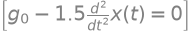

In [16]:
from sympy import Function, init_printing
from sympy.calculus.euler import euler_equations
init_printing()

x = Function('x')
g0 = symbols('g0')
L = (3/4) * (x(t).diff(t))**2 + g0*x(t)
euler_equations(L, x(t), t)

The sympy and analytical solutions are the same.